# 11b GFD External Validation Pilot

This notebook tests whether published or reconstructed DFSI values correspond with independently satellite-observed flood inundation in the Global Flood Database. It is a convergent-validity pilot, not a definitive ground-truth validation and not a weight-optimisation exercise. If Earth Engine exports are missing, it writes empty audit outputs, placeholder figures and a NO-GO report rather than manufacturing statistics.

In [1]:
from pathlib import Path
import hashlib, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.max_columns', 160)
pd.set_option('display.max_rows', 120)
plt.style.use('seaborn-v0_8-whitegrid')
PROJECT_ROOT = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent
BASELINE_PATH = PROJECT_ROOT / 'data' / 'processed' / 'dfsi_verified_baseline.csv'
GFD_DIR = PROJECT_ROOT / 'data' / 'processed' / 'gfd_external_validation'
GFD_METRICS_PATH = GFD_DIR / 'gfd_india_adm2_metrics.csv'
GFD_BOUNDARIES_PATH = GFD_DIR / 'gfd_india_adm2_boundaries.csv'
GFD_EVENT_PATH = GFD_DIR / 'gfd_india_event_inventory.csv'
GFD_DISTRICT_EVENT_PATH = GFD_DIR / 'gfd_india_district_event_metrics.csv'
MATCH_PATH = PROJECT_ROOT / 'outputs' / 'tables' / 'gfd_unique_matches.csv'
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
REPORT_DIR = PROJECT_ROOT / 'outputs' / 'reports'
RAW_DIR = PROJECT_ROOT / 'data' / 'raw'
for d in [TABLE_DIR, FIGURE_DIR, REPORT_DIR, GFD_DIR]: d.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42

def sha256_file(path):
    h=hashlib.sha256()
    with path.open('rb') as f:
        for block in iter(lambda:f.read(1024*1024), b''):
            h.update(block)
    return h.hexdigest()
RAW_HASHES_BEFORE = {x.name: sha256_file(x) for x in sorted(RAW_DIR.glob('*.csv'))}

def placeholder_figure(path, title, message):
    fig, ax = plt.subplots(figsize=(8,4.5), constrained_layout=True)
    ax.axis('off')
    ax.text(0.5,0.62,title,ha='center',va='center',fontsize=14,fontweight='bold')
    ax.text(0.5,0.40,message,ha='center',va='center',fontsize=10,wrap=True)
    fig.savefig(path,dpi=200,bbox_inches='tight')
    plt.close(fig)

baseline = pd.read_csv(BASELINE_PATH)
complete = baseline.query("completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'").copy().reset_index().rename(columns={'index':'dfsi_record_key_int'})
complete['dfsi_record_key'] = complete['dfsi_record_key_int'].astype(str)
assert len(complete) == 709
def read_event_inventory():
    candidates = [GFD_EVENT_PATH, GFD_DIR / 'gfd_india_event_invetory.csv']
    for path in candidates:
        if path.exists():
            return pd.read_csv(path), path
    return pd.DataFrame(), GFD_EVENT_PATH

def load_district_event_exports():
    frames = []
    paths = []
    if GFD_DISTRICT_EVENT_PATH.exists():
        frames.append(pd.read_csv(GFD_DISTRICT_EVENT_PATH))
        paths.append(GFD_DISTRICT_EVENT_PATH)
    for path in sorted(GFD_DIR.glob('gfd_india_district_event_metrics_part_*.csv')):
        frames.append(pd.read_csv(path))
        paths.append(path)
    if frames:
        return pd.concat(frames, ignore_index=True), paths
    return pd.DataFrame(), paths

def build_metrics_from_chunked(boundaries, district_events, events):
    if boundaries.empty or district_events.empty:
        return pd.DataFrame()
    b = boundaries.copy()
    e = district_events.copy()
    b['boundary_shape_id'] = b['boundary_shape_id'].astype(str)
    e['boundary_shape_id'] = e['boundary_shape_id'].astype(str)
    for col in ['district_area_km2']:
        b[col] = pd.to_numeric(b[col], errors='coerce').astype('float64')
    for col in ['flooded_area_km2','flooded_fraction_of_district','mean_inundation_duration','mean_clear_percentage']:
        e[col] = pd.to_numeric(e[col], errors='coerce').astype('float64')
    e['event_date'] = pd.to_datetime(e.get('event_date'), errors='coerce')
    e['area_days'] = e['flooded_area_km2'] * e['mean_inundation_duration']
    e['clear_area_weight'] = e['mean_clear_percentage'] * e['flooded_area_km2']
    grouped = e.groupby('boundary_shape_id', dropna=False).agg(
        gfd_observed_event_count=('gfd_event_id','nunique'),
        cumulative_flooded_area_event_km2=('flooded_area_km2','sum'),
        cumulative_inundation_area_days_km2_days=('area_days','sum'),
        ever_flooded_area_km2=('flooded_area_km2','sum'),
        mean_clear_weight_numerator=('clear_area_weight','sum'),
        clear_weight_denominator=('flooded_area_km2','sum'),
        first_observed_event_date=('event_date','min'),
        last_observed_event_date=('event_date','max')
    ).reset_index()
    out = b.merge(grouped, on='boundary_shape_id', how='left')
    zero_cols = ['gfd_observed_event_count','cumulative_flooded_area_event_km2','cumulative_inundation_area_days_km2_days','ever_flooded_area_km2','mean_clear_weight_numerator','clear_weight_denominator']
    for col in zero_cols:
        out[col] = pd.to_numeric(out[col], errors='coerce').fillna(0.0)
    out['gfd_event_collection_count'] = len(events) if not events.empty else np.nan
    out['ever_flooded_fraction_pct'] = np.where(out['district_area_km2'] > 0, out['ever_flooded_area_km2'] / out['district_area_km2'] * 100, np.nan)
    out['cumulative_flooded_area_event_fraction'] = np.where(out['district_area_km2'] > 0, out['cumulative_flooded_area_event_km2'] / out['district_area_km2'], np.nan)
    out['cumulative_inundation_area_days_per_km2'] = np.where(out['district_area_km2'] > 0, out['cumulative_inundation_area_days_km2_days'] / out['district_area_km2'], np.nan)
    out['mean_flooded_pixel_event_count'] = np.nan
    out['maximum_flooded_pixel_event_count'] = np.nan
    out['mean_clear_perc_over_observed_flood_pixels'] = np.where(out['clear_weight_denominator'] > 0, out['mean_clear_weight_numerator'] / out['clear_weight_denominator'], np.nan)
    for col in ['first_observed_event_date','last_observed_event_date']:
        out[col] = pd.to_datetime(out[col], errors='coerce').dt.strftime('%Y-%m-%d')
    out = out.drop(columns=['mean_clear_weight_numerator','clear_weight_denominator'])
    return out

metrics = pd.read_csv(GFD_METRICS_PATH) if GFD_METRICS_PATH.exists() else pd.DataFrame()
boundaries = pd.read_csv(GFD_BOUNDARIES_PATH) if GFD_BOUNDARIES_PATH.exists() else pd.DataFrame()
events, event_inventory_path = read_event_inventory()
district_events, district_event_paths = load_district_event_exports()
if metrics.empty and not boundaries.empty and not district_events.empty:
    metrics = build_metrics_from_chunked(boundaries, district_events, events)
    metrics.to_csv(GFD_METRICS_PATH, index=False)
matches = pd.read_csv(MATCH_PATH) if MATCH_PATH.exists() else pd.DataFrame()
print('Complete DFSI records:', len(complete))
print('GFD metrics rows:', len(metrics), 'file exists:', GFD_METRICS_PATH.exists())
print('GFD boundary rows:', len(boundaries), 'file exists:', GFD_BOUNDARIES_PATH.exists())
print('GFD events rows:', len(events), 'source:', event_inventory_path.relative_to(PROJECT_ROOT) if event_inventory_path.exists() else 'missing')
print('GFD district-event rows:', len(district_events), 'files:', [p.name for p in district_event_paths])
print('Unique match rows:', len(matches), 'file exists:', MATCH_PATH.exists())

Complete DFSI records: 709
GFD metrics rows: 735 file exists: True
GFD boundary rows: 735 file exists: True
GFD events rows: 192 source: data/processed/gfd_external_validation/gfd_india_event_inventory.csv
GFD district-event rows: 16402 files: ['gfd_india_district_event_metrics_part_00.csv', 'gfd_india_district_event_metrics_part_01.csv', 'gfd_india_district_event_metrics_part_02.csv', 'gfd_india_district_event_metrics_part_03.csv', 'gfd_india_district_event_metrics_part_04.csv', 'gfd_india_district_event_metrics_part_05.csv', 'gfd_india_district_event_metrics_part_06.csv', 'gfd_india_district_event_metrics_part_07.csv', 'gfd_india_district_event_metrics_part_08.csv', 'gfd_india_district_event_metrics_part_09.csv', 'gfd_india_district_event_metrics_part_10.csv', 'gfd_india_district_event_metrics_part_11.csv', 'gfd_india_district_event_metrics_part_12.csv', 'gfd_india_district_event_metrics_part_13.csv', 'gfd_india_district_event_metrics_part_14.csv', 'gfd_india_district_event_metrics_p

## Build Analysis Sample

In [2]:
required_metric_cols = ['boundary_shape_id','ever_flooded_fraction_pct','cumulative_flooded_area_event_fraction','cumulative_inundation_area_days_per_km2','ever_flooded_area_km2','cumulative_flooded_area_event_km2','mean_clear_perc_over_observed_flood_pixels','district_area_km2']
can_analyze = (GFD_METRICS_PATH.exists() and GFD_EVENT_PATH.exists() and MATCH_PATH.exists() and not metrics.empty and not matches.empty and all(c in metrics.columns for c in required_metric_cols))
if can_analyze:
    accepted = matches.query("match_status == 'accepted_unique'").copy() if 'match_status' in matches.columns else matches.copy()
    accepted['dfsi_record_key'] = accepted['dfsi_record_key'].astype(str)
    accepted['boundary_shape_id'] = accepted['boundary_shape_id'].astype(str)
    metrics['boundary_shape_id'] = metrics['boundary_shape_id'].astype(str)
    analysis = complete.merge(accepted, on='dfsi_record_key', how='inner', suffixes=('', '_match')).merge(metrics, on='boundary_shape_id', how='inner', suffixes=('', '_gfd'))
else:
    analysis = pd.DataFrame()
print('Can analyze:', can_analyze)
print('Analysis rows:', len(analysis))

Can analyze: True
Analysis rows: 657


## Measures and Statistical Functions

In [3]:
primary_outcomes = ['ever_flooded_fraction_pct','cumulative_flooded_area_event_fraction','cumulative_inundation_area_days_per_km2']
secondary_outcomes = ['ever_flooded_area_km2','cumulative_flooded_area_event_km2']
index_measures = ['published_dfsi','reconstructed_dfsi','term_flood_events','term_duration','term_fatalities','term_injured','term_flooded_area','term_population','equal_weight_log_component_index']
index_labels = {'published_dfsi':'Published DFSI','reconstructed_dfsi':'Reconstructed DFSI','term_flood_events':'Flood-event component','term_duration':'Duration component','term_fatalities':'Fatality component','term_injured':'Injury component','term_flooded_area':'Flooded-area component','term_population':'Population component','equal_weight_log_component_index':'Equal-weight log index'}
primary_burden = 'cumulative_inundation_area_days_per_km2'
if can_analyze and len(analysis):
    for c in ['flood_event_count','mean_flood_duration','fatalities','injured','corrected_percent_flooded_area','population','published_dfsi','reconstructed_dfsi'] + primary_outcomes + secondary_outcomes + ['mean_clear_perc_over_observed_flood_pixels','district_area_km2']:
        analysis[c] = pd.to_numeric(analysis[c], errors='coerce')
    analysis['term_flood_events'] = np.log10(1 + analysis['flood_event_count'])
    analysis['term_duration'] = np.log10(1 + analysis['mean_flood_duration'])
    analysis['term_fatalities'] = 2 * np.log10(1 + analysis['fatalities'])
    analysis['term_injured'] = np.log10(1 + analysis['injured'])
    analysis['term_flooded_area'] = np.log10(1 + analysis['corrected_percent_flooded_area'])
    analysis['term_population'] = np.log10(analysis['population'])
    analysis['equal_weight_log_component_index'] = np.log10(1 + analysis['flood_event_count']) + np.log10(1 + analysis['mean_flood_duration']) + np.log10(1 + analysis['fatalities']) + np.log10(1 + analysis['injured']) + np.log10(1 + analysis['corrected_percent_flooded_area']) + np.log10(analysis['population'])
    analysis.to_csv(TABLE_DIR / 'gfd_validation_analysis_sample.csv', index=False)
else:
    pd.DataFrame().to_csv(TABLE_DIR / 'gfd_validation_analysis_sample.csv', index=False)

def bh_fdr(pvals):
    p=np.asarray(pvals,dtype=float); out=np.full_like(p,np.nan,dtype=float); valid=np.isfinite(p); pv=p[valid]
    if len(pv)==0: return out
    order=np.argsort(pv); ranked=pv[order]; m=len(ranked); adj=ranked*m/np.arange(1,m+1); adj=np.minimum.accumulate(adj[::-1])[::-1]; adj=np.clip(adj,0,1); temp=np.empty_like(adj); temp[order]=adj; out[valid]=temp; return out

def boot_ci(x,y,n_resamples=2000,seed=42):
    x=np.asarray(x,dtype=float); y=np.asarray(y,dtype=float); mask=np.isfinite(x)&np.isfinite(y); x=x[mask]; y=y[mask]; n=len(x)
    if n<4 or np.nanstd(x)==0 or np.nanstd(y)==0: return (np.nan,np.nan)
    rng=np.random.default_rng(seed); vals=[]
    for _ in range(n_resamples):
        idx=rng.integers(0,n,size=n)
        if np.nanstd(x[idx]) and np.nanstd(y[idx]): vals.append(stats.spearmanr(x[idx],y[idx]).statistic)
    return (float(np.percentile(vals,2.5)), float(np.percentile(vals,97.5))) if vals else (np.nan,np.nan)

def top10_overlap(x,y):
    d=pd.DataFrame({'x':x,'y':y}).dropna(); n=len(d)
    if n==0: return {'usable_districts':0,'top10_n':0,'top10_overlap_count':0,'jaccard_similarity':np.nan}
    k=max(1,int(math.ceil(0.10*n))); a=set(d.sort_values('x',ascending=False).head(k).index); b=set(d.sort_values('y',ascending=False).head(k).index); inter=len(a&b); union=len(a|b)
    return {'usable_districts':n,'top10_n':k,'top10_overlap_count':inter,'jaccard_similarity':inter/union if union else np.nan}

def corr_rows(frame,label):
    rows=[]
    for outcome in primary_outcomes+secondary_outcomes:
        if outcome not in frame: continue
        for idxm in index_measures:
            if idxm not in frame: continue
            d=frame[[idxm,outcome]].dropna(); n=len(d)
            base={'sensitivity':label,'index_measure':idxm,'index_label':index_labels[idxm],'satellite_outcome':outcome,'usable_districts':n}
            if n>=4 and d[idxm].nunique()>1 and d[outcome].nunique()>1:
                sp=stats.spearmanr(d[idxm],d[outcome]); kt=stats.kendalltau(d[idxm],d[outcome]); lo,hi=boot_ci(d[idxm],d[outcome],seed=RANDOM_SEED); top=top10_overlap(d[idxm],d[outcome])
                base.update({'spearman_correlation':float(sp.statistic),'spearman_p_value':float(sp.pvalue),'kendall_correlation':float(kt.statistic),'kendall_p_value':float(kt.pvalue),'bootstrap_spearman_ci_low':lo,'bootstrap_spearman_ci_high':hi,**top})
            else:
                base.update({'spearman_correlation':np.nan,'spearman_p_value':np.nan,'kendall_correlation':np.nan,'kendall_p_value':np.nan,'bootstrap_spearman_ci_low':np.nan,'bootstrap_spearman_ci_high':np.nan,'top10_n':np.nan,'top10_overlap_count':np.nan,'jaccard_similarity':np.nan})
            rows.append(base)
    return rows

## Run Analysis or Write Transparent Empty Outputs

In [4]:
if can_analyze and len(analysis):
    samples=[('national',analysis.copy()),('excluding_zero_mapped_gfd_floodwater',analysis.loc[analysis['ever_flooded_area_km2'].fillna(0)>0].copy())]
    clear=analysis['mean_clear_perc_over_observed_flood_pixels']; q10=clear.dropna().quantile(0.10) if clear.notna().any() else np.nan
    samples.append(('excluding_lowest_clear_observation_decile', analysis.loc[clear.isna() | (clear > q10)].copy() if np.isfinite(q10) else analysis.iloc[0:0].copy()))
    rows=[]
    for label,frame in samples: rows.extend(corr_rows(frame,label))
    correlations=pd.DataFrame(rows); correlations['spearman_p_value_fdr_bh']=bh_fdr(correlations['spearman_p_value'])
    qframe=analysis[['published_dfsi']+primary_outcomes+secondary_outcomes].dropna(subset=['published_dfsi']).copy(); qframe['dfsi_quintile']=pd.qcut(qframe['published_dfsi'],q=5,labels=['Q1 lowest','Q2','Q3','Q4','Q5 highest'],duplicates='drop')
    quintiles=[]
    for outcome in primary_outcomes+secondary_outcomes:
        for q,g in qframe.groupby('dfsi_quintile', observed=True):
            vals=g[outcome].dropna(); quintiles.append({'satellite_outcome':outcome,'dfsi_quintile':str(q),'districts':len(vals),'median_satellite_outcome':vals.median() if len(vals) else np.nan,'mean_satellite_outcome':vals.mean() if len(vals) else np.nan})
    quintiles=pd.DataFrame(quintiles)
    top10=[]
    for outcome in primary_outcomes+secondary_outcomes:
        for idxm in index_measures:
            row=top10_overlap(analysis[idxm],analysis[outcome]); row.update({'index_measure':idxm,'index_label':index_labels[idxm],'satellite_outcome':outcome}); top10.append(row)
    top10=pd.DataFrame(top10)
    benchmark=correlations.query("sensitivity == 'national' and satellite_outcome in @primary_outcomes").copy()
    benchmark['benchmark_group']=np.select([benchmark['index_measure'].eq('published_dfsi'), benchmark['index_measure'].eq('reconstructed_dfsi'), benchmark['index_measure'].eq('equal_weight_log_component_index'), benchmark['index_measure'].str.startswith('term_')], ['published_dfsi','reconstructed_dfsi','equal_weight','individual_component'], default='other')
else:
    correlations=pd.DataFrame(columns=['sensitivity','index_measure','index_label','satellite_outcome','usable_districts','spearman_correlation','spearman_p_value','kendall_correlation','kendall_p_value','bootstrap_spearman_ci_low','bootstrap_spearman_ci_high','top10_n','top10_overlap_count','jaccard_similarity','spearman_p_value_fdr_bh'])
    quintiles=pd.DataFrame(columns=['satellite_outcome','dfsi_quintile','districts','median_satellite_outcome','mean_satellite_outcome'])
    top10=pd.DataFrame(columns=['usable_districts','top10_n','top10_overlap_count','jaccard_similarity','index_measure','index_label','satellite_outcome'])
    benchmark=pd.DataFrame(columns=list(correlations.columns)+['benchmark_group'])
for name,df in [('gfd_validation_correlations.csv',correlations),('gfd_validation_dfsi_quintiles.csv',quintiles),('gfd_validation_top10_overlap.csv',top10),('gfd_validation_benchmark_comparison.csv',benchmark)]:
    df.to_csv(TABLE_DIR/name,index=False)
print('Correlation rows:', len(correlations))
display(correlations.head())

Correlation rows: 135


,sensitivity,index_measure,index_label,satellite_outcome,usable_districts,spearman_correlation,spearman_p_value,kendall_correlation,kendall_p_value,bootstrap_spearman_ci_low,bootstrap_spearman_ci_high,top10_n,top10_overlap_count,jaccard_similarity,spearman_p_value_fdr_bh
0,national,published_dfsi,Published DFSI,ever_flooded_fraction_pct,657,0.361124,1.140709e-21,0.249481,1.141050e-21,0.283925,0.433153,66,27,0.257143,2.524519e-21
1,national,reconstructed_dfsi,Reconstructed DFSI,ever_flooded_fraction_pct,657,0.379254,6.663812e-24,0.262571,7.883720e-24,0.305725,0.451779,66,27,0.257143,1.763950e-23
2,national,term_flood_events,Flood-event component,ever_flooded_fraction_pct,657,0.313154,2.050462e-16,0.221064,5.018507e-17,0.235493,0.387869,66,20,0.178571,2.853736e-16
3,national,term_duration,Duration component,ever_flooded_fraction_pct,657,0.394818,6.179085e-26,0.269777,9.659649e-24,0.331571,0.456045,66,12,0.100000,2.085441e-25
4,national,term_fatalities,Fatality component,ever_flooded_fraction_pct,657,0.293876,1.486209e-14,0.201539,1.429321e-14,0.218371,0.368969,66,15,0.128205,1.892813e-14


## Figures

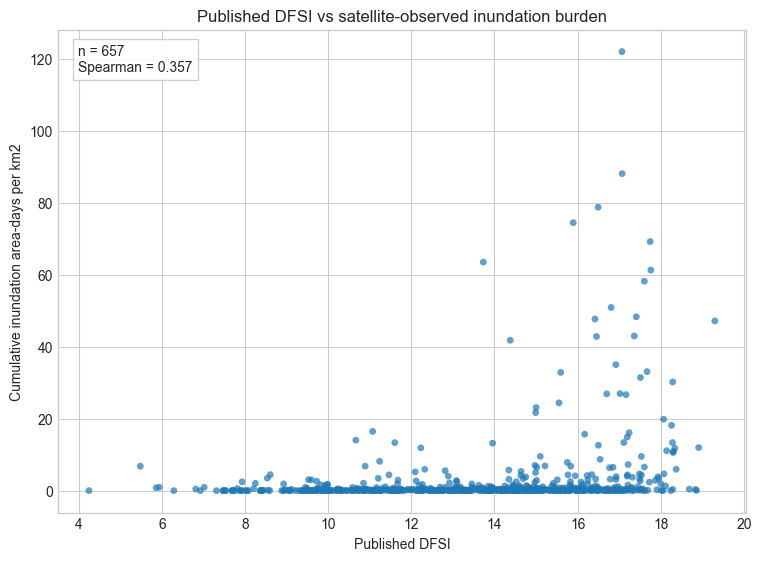

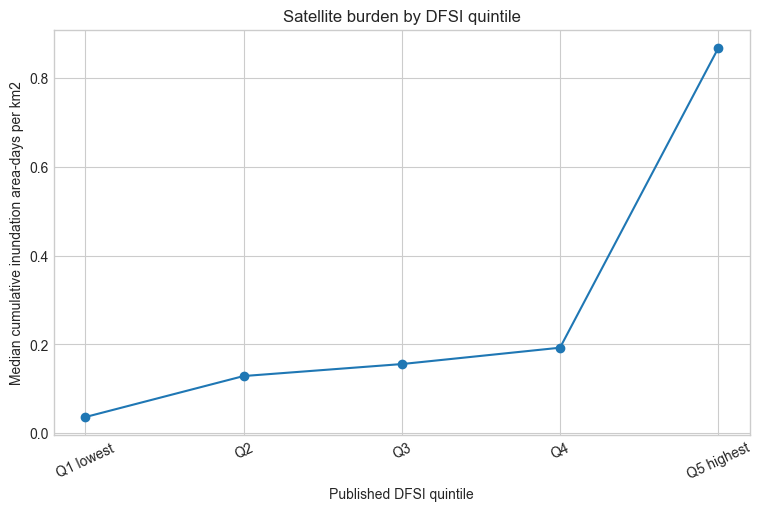

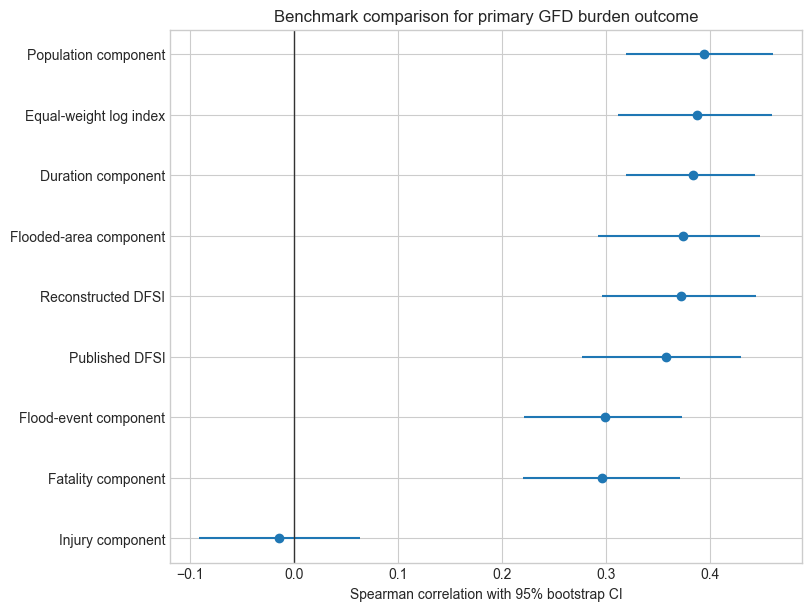

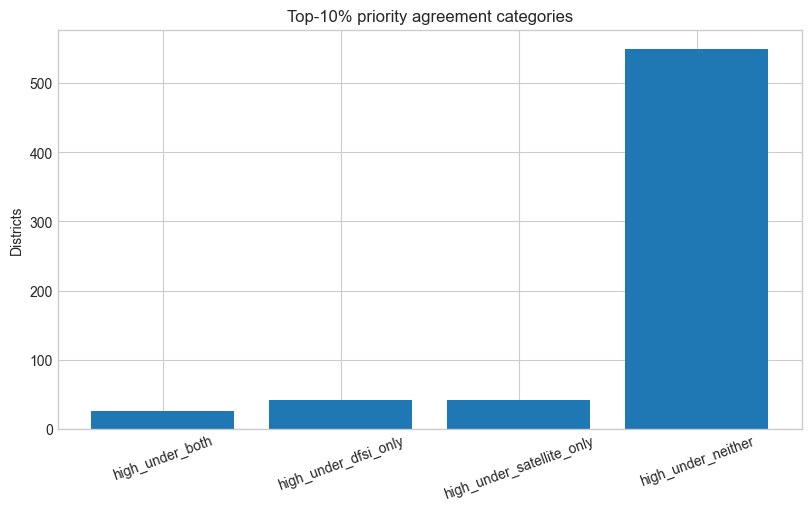

In [5]:
if can_analyze and len(analysis):
    dat=analysis[['published_dfsi',primary_burden]].dropna(); fig,ax=plt.subplots(figsize=(7.5,5.5),constrained_layout=True); ax.scatter(dat['published_dfsi'],dat[primary_burden],s=24,alpha=0.7,edgecolor='none'); rho=stats.spearmanr(dat['published_dfsi'],dat[primary_burden]).statistic if len(dat)>=4 and dat['published_dfsi'].nunique()>1 and dat[primary_burden].nunique()>1 else np.nan; ax.set_xlabel('Published DFSI'); ax.set_ylabel('Cumulative inundation area-days per km2'); ax.set_title('Published DFSI vs satellite-observed inundation burden'); ax.text(0.03,0.97,f'n = {len(dat)}\nSpearman = {rho:.3f}' if np.isfinite(rho) else f'n = {len(dat)}\nSpearman = NA',transform=ax.transAxes,va='top',bbox={'facecolor':'white','edgecolor':'#cccccc','alpha':0.9}); fig.savefig(FIGURE_DIR/'gfd_dfsi_scatter.png',dpi=250,bbox_inches='tight'); plt.show()
    qplot=quintiles.query('satellite_outcome == @primary_burden'); fig,ax=plt.subplots(figsize=(7.5,5),constrained_layout=True); ax.plot(qplot['dfsi_quintile'],qplot['median_satellite_outcome'],marker='o'); ax.set_xlabel('Published DFSI quintile'); ax.set_ylabel('Median cumulative inundation area-days per km2'); ax.tick_params(axis='x',rotation=25); ax.set_title('Satellite burden by DFSI quintile'); fig.savefig(FIGURE_DIR/'gfd_outcome_by_dfsi_quintile.png',dpi=250,bbox_inches='tight'); plt.show()
    bplot=benchmark.query('satellite_outcome == @primary_burden').sort_values('spearman_correlation'); fig,ax=plt.subplots(figsize=(8,6),constrained_layout=True); y=np.arange(len(bplot)); ax.errorbar(bplot['spearman_correlation'],y,xerr=[bplot['spearman_correlation']-bplot['bootstrap_spearman_ci_low'],bplot['bootstrap_spearman_ci_high']-bplot['spearman_correlation']],fmt='o'); ax.axvline(0,color='#333333',linewidth=1); ax.set_yticks(y); ax.set_yticklabels(bplot['index_label']); ax.set_xlabel('Spearman correlation with 95% bootstrap CI'); ax.set_title('Benchmark comparison for primary GFD burden outcome'); fig.savefig(FIGURE_DIR/'gfd_benchmark_comparison.png',dpi=250,bbox_inches='tight'); plt.show()
    pa=analysis[['district_name','State_Name','published_dfsi',primary_burden]].dropna().copy(); k=max(1,int(math.ceil(0.10*len(pa)))); a=set(pa.sort_values('published_dfsi',ascending=False).head(k).index); b=set(pa.sort_values(primary_burden,ascending=False).head(k).index); pa['priority_agreement_category']=np.select([pa.index.isin(a)&pa.index.isin(b), pa.index.isin(a)&~pa.index.isin(b), ~pa.index.isin(a)&pa.index.isin(b)], ['high_under_both','high_under_dfsi_only','high_under_satellite_only'], default='high_under_neither'); counts=pa['priority_agreement_category'].value_counts().reindex(['high_under_both','high_under_dfsi_only','high_under_satellite_only','high_under_neither']).fillna(0); fig,ax=plt.subplots(figsize=(8,5),constrained_layout=True); ax.bar(counts.index,counts.values); ax.set_ylabel('Districts'); ax.set_title('Top-10% priority agreement categories'); ax.tick_params(axis='x',rotation=20); fig.savefig(FIGURE_DIR/'gfd_priority_agreement.png',dpi=250,bbox_inches='tight'); plt.show(); pa.to_csv(TABLE_DIR/'gfd_priority_agreement_categories.csv',index=False)
else:
    msg='GFD Earth Engine exports or unique accepted boundary matches are missing. Run the Code Editor export and rerun notebooks 11a and 11b.'
    for fn,title in [('gfd_dfsi_scatter.png','GFD DFSI scatter unavailable'),('gfd_outcome_by_dfsi_quintile.png','GFD quintile figure unavailable'),('gfd_benchmark_comparison.png','GFD benchmark figure unavailable'),('gfd_priority_agreement.png','GFD priority agreement unavailable')]: placeholder_figure(FIGURE_DIR/fn,title,msg)
    pd.DataFrame().to_csv(TABLE_DIR/'gfd_priority_agreement_categories.csv',index=False)
for fn in ['gfd_dfsi_scatter.png','gfd_outcome_by_dfsi_quintile.png','gfd_benchmark_comparison.png','gfd_priority_agreement.png']:
    assert (FIGURE_DIR/fn).exists() and (FIGURE_DIR/fn).stat().st_size>0

## Go/No-Go Report

In [6]:
if can_analyze and len(analysis):
    matched_unique=len(analysis); matched_pct=matched_unique/len(complete)*100; nonzero=int((analysis['ever_flooded_area_km2'].fillna(0)>0).sum()); clear_summary=analysis['mean_clear_perc_over_observed_flood_pixels'].describe().to_dict(); event_count=len(events) if not events.empty else int(metrics['gfd_event_collection_count'].dropna().max()) if 'gfd_event_collection_count' in metrics and metrics['gfd_event_collection_count'].notna().any() else 0; boundary_count=len(metrics); primary_corr=correlations.query("sensitivity == 'national' and index_measure == 'published_dfsi' and satellite_outcome == @primary_burden"); primary_line='No primary correlation available.' if primary_corr.empty else primary_corr.iloc[0].to_dict(); top_primary=top10.query("index_measure == 'published_dfsi' and satellite_outcome == @primary_burden"); top_line='No top-10 overlap available.' if top_primary.empty else top_primary.iloc[0].to_dict(); area_dat=analysis[['district_area_km2',primary_burden]].dropna(); area_corr=abs(stats.spearmanr(area_dat['district_area_km2'],area_dat[primary_burden]).statistic) if len(area_dat)>=4 else np.nan; burden=analysis[primary_burden].fillna(0).sort_values(ascending=False); top2_share=float(burden.head(2).sum()/burden.sum()) if burden.sum()>0 else np.nan; criteria={'at_least_70_percent_matched': matched_pct>=70, 'meaningful_nonzero_observations': nonzero>=max(20,0.05*matched_unique), 'not_dominated_by_area': (not np.isfinite(area_corr)) or area_corr<0.85, 'not_dominated_by_one_or_two_districts': (not np.isfinite(top2_share)) or top2_share<0.50}; decision='GO WITH LIMITATIONS' if criteria['at_least_70_percent_matched'] and criteria['meaningful_nonzero_observations'] else 'NO-GO'
else:
    matched_unique=0; matched_pct=0.0; nonzero=0; event_count=len(events) if not events.empty else 0; boundary_count=len(metrics) if not metrics.empty else 0; clear_summary={}; primary_line='Unavailable because GFD exports and/or unique accepted matches are missing.'; top_line='Unavailable because GFD exports and/or unique accepted matches are missing.'; criteria={'at_least_70_percent_matched':False,'meaningful_nonzero_observations':False,'not_dominated_by_area':False,'not_dominated_by_one_or_two_districts':False}; decision='NO-GO'
report = f'''# GFD External Validation Go/No-Go Report

## Data Feasibility

- India-related GFD events: {event_count}
- Indian boundary geometries in downloaded metrics: {boundary_count}
- Complete DFSI districts: {len(complete)}
- Unique accepted DFSI-boundary matches used: {matched_unique} ({matched_pct:.1f}%)
- Matched districts with non-zero satellite-observed floodwater: {nonzero}
- Observation-quality summary from `mean_clear_perc_over_observed_flood_pixels`: {clear_summary}
- Unresolved boundary problems: see `outputs/tables/gfd_unmatched_dfsi_records.csv`, `outputs/tables/gfd_unmatched_boundary_records.csv` and `outputs/tables/gfd_ambiguous_matches.csv`.

## Preliminary Validity Results

- Primary outcome: `{primary_burden}`.
- Primary published-DFSI correlation row: {primary_line}
- Published-DFSI top-10% overlap row: {top_line}
- Benchmark comparison table: `outputs/tables/gfd_validation_benchmark_comparison.csv`.
- Agreement/disagreement district categories: `outputs/tables/gfd_priority_agreement_categories.csv`.

## Scientific Interpretation

This pilot is a convergent-validity test. GFD provides an independent satellite-observed sample of mapped physical inundation for 2000-2018; DFSI covers a longer historical period and combines hazard, exposure and human impacts. Weak correspondence would not automatically invalidate DFSI, and stronger correspondence for any one specification would not identify a universally correct index.

## Project Decision Rules

{criteria}

## Current Decision

**{decision}**

If the current decision is `NO-GO` because exports are missing, run `gee/11_gfd_external_validation_export_chunked.js` in the Earth Engine Code Editor, place `gfd_india_adm2_boundaries.csv`, `gfd_india_event_inventory.csv` and all `gfd_india_district_event_metrics_part_*.csv` files in `data/processed/gfd_external_validation/`, rerun `notebooks/11a_gfd_boundary_matching.ipynb`, review any ambiguous matches and then rerun this notebook.
'''
(REPORT_DIR/'gfd_external_validation_go_no_go.md').write_text(report, encoding='utf-8')
print(report)
RAW_HASHES_AFTER={x.name: sha256_file(x) for x in sorted(RAW_DIR.glob('*.csv'))}
assert RAW_HASHES_BEFORE == RAW_HASHES_AFTER, 'data/raw changed during pilot analysis.'

# GFD External Validation Go/No-Go Report

## Data Feasibility

- India-related GFD events: 192
- Indian boundary geometries in downloaded metrics: 735
- Complete DFSI districts: 709
- Unique accepted DFSI-boundary matches used: 657 (92.7%)
- Matched districts with non-zero satellite-observed floodwater: 639
- Observation-quality summary from `mean_clear_perc_over_observed_flood_pixels`: {'count': 639.0, 'mean': 0.9794151498216714, 'std': 0.012688654722024096, 'min': 0.9169611819102688, '25%': 0.9702529253228611, '50%': 0.981559173899506, '75%': 0.9898902841883029, 'max': 1.0}
- Unresolved boundary problems: see `outputs/tables/gfd_unmatched_dfsi_records.csv`, `outputs/tables/gfd_unmatched_boundary_records.csv` and `outputs/tables/gfd_ambiguous_matches.csv`.

## Preliminary Validity Results

- Primary outcome: `cumulative_inundation_area_days_per_km2`.
- Primary published-DFSI correlation row: {'sensitivity': 'national', 'index_measure': 'published_dfsi', 'index_label': 'Published DFSI